# SCIKIT-LEARN MASTERY — NOTEBOOK 11
## Chapters 61–66: Computational Performance → Sparse Matrices → Text ML with Scikit-learn → NLP Pipelines → Image/Computer Vision Connection → Model Persistence

Continuing directly from Notebook 10.

### SCIKIT-LEARN MASTERY PROGRESS
- [x] Chapters 1–60 *(Notebooks 1–10)*
- [x] Computational Performance
- [x] Sparse Matrices
- [x] Text ML with Scikit-learn
- [x] NLP Pipelines
- [x] Image/Computer Vision Connection
- [x] Model Persistence


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
np.random.seed(42)


---
# CHAPTER 61 — COMPUTATIONAL PERFORMANCE

## 1. Concept
Before optimizing anything, always answer: **"where is the actual bottleneck?"** — preprocessing, model fitting, cross-validation overhead, or prediction? Guessing and optimizing the wrong stage wastes effort; this chapter builds the profiling habit first, then the specific techniques.

## 2. Profiling a Full Pipeline, Stage by Stage


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

np.random.seed(61)
n = 15_000
df_perf = pd.DataFrame({
    "num1": np.random.randn(n), "num2": np.random.randn(n), "num3": np.random.randn(n),
    "cat1": np.random.choice(["A", "B", "C", "D"], n),
})
y_perf = np.random.randint(0, 2, n)

preprocessor_perf = ColumnTransformer([
    ("num", StandardScaler(), ["num1", "num2", "num3"]),
    ("cat", OneHotEncoder(), ["cat1"]),
])

# STAGE 1: preprocessing alone
start = time.time()
X_transformed = preprocessor_perf.fit_transform(df_perf)
t_preprocess = time.time() - start

# STAGE 2: model fitting alone (on already-transformed data)
start = time.time()
RandomForestClassifier(n_estimators=100, random_state=42).fit(X_transformed, y_perf)
t_fit = time.time() - start

# STAGE 3: full pipeline with 5-fold cross-validation
full_pipeline_perf = Pipeline([("prep", preprocessor_perf), ("model", RandomForestClassifier(n_estimators=100, random_state=42))])
start = time.time()
cross_val_score(full_pipeline_perf, df_perf, y_perf, cv=5, n_jobs=1)   # n_jobs=1 -- sequential, for isolated timing
t_cv_sequential = time.time() - start

start = time.time()
cross_val_score(full_pipeline_perf, df_perf, y_perf, cv=5, n_jobs=-1)   # n_jobs=-1 -- parallel across folds
t_cv_parallel = time.time() - start

print(f"{'Stage':<35}{'Time (s)':>12}")
print(f"{'Preprocessing alone':<35}{t_preprocess:>12.3f}")
print(f"{'Model fit alone (on transformed X)':<35}{t_fit:>12.3f}")
print(f"{'5-fold CV, n_jobs=1 (sequential)':<35}{t_cv_sequential:>12.3f}")
print(f"{'5-fold CV, n_jobs=-1 (parallel)':<35}{t_cv_parallel:>12.3f}")
print(f"\nSpeedup from n_jobs=-1: {t_cv_sequential/t_cv_parallel:.2f}x")


Stage                                  Time (s)
Preprocessing alone                       0.065
Model fit alone (on transformed X)       13.677
5-fold CV, n_jobs=1 (sequential)         27.413
5-fold CV, n_jobs=-1 (parallel)          18.852

Speedup from n_jobs=-1: 1.45x


### Interpretation
This kind of stage-by-stage timing breakdown directly reveals **where** time is actually being spent — in this case, model fitting (Random Forest training) is almost certainly the dominant cost relative to preprocessing, telling you exactly where optimization effort should focus (fewer/shallower trees, `HistGradientBoosting` instead, or genuine data reduction) rather than, say, over-engineering preprocessing speed that was never the bottleneck.

## 3. Techniques for Speeding Up Each Stage
| Bottleneck | Techniques |
|---|---|
| Model fitting (many models/CV folds) | `n_jobs=-1` for embarrassingly parallel work (cross-validation, grid search, Random Forest's own tree-building); switch to a faster algorithm (`HistGradientBoosting` over `GradientBoosting`, Chapter 22) |
| Preprocessing | Vectorized Pandas/NumPy operations over Python loops; sparse representations for high-cardinality categoricals (Chapter 62) |
| Feature count | Feature selection (Chapter 32) or dimensionality reduction (Chapter 34) to reduce the columns models must process |
| Dataset size | Subsample for initial development/exploration iterations, scale up only for final training runs; `MiniBatchKMeans`/`SGDClassifier`-style incremental algorithms for genuinely huge data |
| Memory | Sparse matrices (Chapter 62); `float32` instead of `float64` where precision allows; process in batches (`partial_fit()`, where supported) |

### `n_jobs` — Where Parallelism Actually Helps


In [3]:
# n_jobs=-1 helps ANYTHING with independent, repeated sub-computations:
# cross-validation folds, grid/random search combinations, and (for some models) internal tree-building

from sklearn.model_selection import GridSearchCV

start = time.time()
GridSearchCV(
    RandomForestClassifier(random_state=42), param_grid={"n_estimators": [50, 100], "max_depth": [4, 8]},
    cv=3, n_jobs=1,
).fit(df_perf.sample(5000, random_state=1)[["num1", "num2", "num3"]], y_perf[:5000])
t_grid_seq = time.time() - start

start = time.time()
GridSearchCV(
    RandomForestClassifier(random_state=42), param_grid={"n_estimators": [50, 100], "max_depth": [4, 8]},
    cv=3, n_jobs=-1,
).fit(df_perf.sample(5000, random_state=1)[["num1", "num2", "num3"]], y_perf[:5000])
t_grid_par = time.time() - start

print(f"GridSearchCV n_jobs=1:  {t_grid_seq:.3f}s")
print(f"GridSearchCV n_jobs=-1: {t_grid_par:.3f}s   (speedup: {t_grid_seq/t_grid_par:.2f}x)")


GridSearchCV n_jobs=1:  6.014s
GridSearchCV n_jobs=-1: 4.163s   (speedup: 1.44x)


### Common Mistakes
- Optimizing preprocessing code heavily when profiling would have revealed model fitting is the actual bottleneck (or vice versa) — always profile before optimizing.
- Setting `n_jobs=-1` at **multiple nested levels simultaneously** (e.g., both `GridSearchCV(n_jobs=-1)` and `RandomForestClassifier(n_jobs=-1)` inside it) — can cause oversubscription (more threads/processes spawned than CPU cores available), sometimes actually *slowing things down* due to context-switching overhead; generally parallelize at only the outermost level for a given resource.
- Assuming more `n_estimators`/deeper trees is always worth the computational cost without checking whether it meaningfully improves validation performance (Chapter 51's validation curves are the correct tool to check this before committing to expensive settings).

### Best Practices
- Profile with explicit stage-by-stage timing (as done above) before optimizing anything.
- Use `n_jobs=-1` at exactly one level of a nested computation (usually the outermost — `GridSearchCV`/`cross_val_score` — rather than also on the inner model).
- Subsample aggressively during early development/debugging iterations; only scale to the full dataset for final runs.

### Interview Insight
**Q: Your training pipeline takes 2 hours. What's your systematic approach to speeding it up?**
A: First, profile each stage in isolation (preprocessing, model fitting, cross-validation/search overhead) to identify where the actual time is spent — optimizing the wrong stage wastes effort. If model fitting dominates: check whether `n_jobs=-1` is being used for parallelizable work (CV folds, grid search combinations, tree-building), consider a faster algorithm (`HistGradientBoosting` over `GradientBoosting`), and use validation curves to confirm whether expensive settings (very high `n_estimators`, very deep trees) are actually earning their cost in validation performance, not just training time. If preprocessing dominates: check for non-vectorized Python loops that should be vectorized Pandas/NumPy operations, and consider sparse representations for high-cardinality categorical encoding. Throughout, subsample the data for rapid iteration during development, and reserve the full-scale run for the final, validated configuration.

### Quiz (Chapter 61)
1. Why must you profile before optimizing, rather than guessing which stage is slow?
2. Why can setting `n_jobs=-1` at multiple nested levels simultaneously sometimes slow things down?
3. Name three distinct optimization techniques, each targeting a different specific bottleneck.


---
# CHAPTER 62 — SPARSE MATRICES

## 1. Concept
A **sparse matrix** stores only the non-zero values (plus their positions), rather than every cell including all the zeros — for data that's genuinely mostly zero (one-hot encoded categorical columns with many categories, TF-IDF text representations), this is often a **10-1000x memory reduction**, and can make the difference between "fits in memory" and "crashes."

## 2. CSR/CSC — The Two Common Sparse Formats
- **CSR (Compressed Sparse Row)**: efficient for row-wise operations (e.g., iterating samples) — the default `OneHotEncoder`/`TfidfVectorizer` output format.
- **CSC (Compressed Sparse Column)**: efficient for column-wise operations (e.g., some linear algebra) — used internally by some algorithms.


In [4]:
from sklearn.preprocessing import OneHotEncoder
from scipy import sparse
import sys

# A HIGH-cardinality categorical column -- exactly where sparsity matters most
np.random.seed(62)
n_sparse = 10_000
high_cardinality_col = np.random.choice([f"category_{i}" for i in range(500)], n_sparse).reshape(-1, 1)

ohe_sparse = OneHotEncoder(sparse_output=True)    # default -- returns a SciPy sparse matrix
ohe_dense = OneHotEncoder(sparse_output=False)     # forces a dense NumPy array

X_sparse = ohe_sparse.fit_transform(high_cardinality_col)
X_dense = ohe_dense.fit_transform(high_cardinality_col)

print("Sparse matrix type:", type(X_sparse))
print("Sparse matrix shape:", X_sparse.shape)
print(f"Sparse matrix actual memory:  {X_sparse.data.nbytes + X_sparse.indices.nbytes + X_sparse.indptr.nbytes:,} bytes")
print(f"Dense array memory:           {X_dense.nbytes:,} bytes")
print(f"Memory reduction: {X_dense.nbytes / (X_sparse.data.nbytes + X_sparse.indices.nbytes + X_sparse.indptr.nbytes):.1f}x")


Sparse matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Sparse matrix shape: (10000, 500)
Sparse matrix actual memory:  160,004 bytes
Dense array memory:           40,000,000 bytes
Memory reduction: 250.0x


### Line-by-Line Explanation
- With 500 possible categories, one-hot encoding produces 500 output columns, but **each row has exactly one `1` and 499 zeros** — a sparse matrix stores only that single non-zero value's position per row (plus small bookkeeping arrays), while a dense array must physically allocate space for every one of the 5,000,000 (10,000 × 500) cells, the vast majority of which are zero.
- `X_sparse.data`, `.indices`, `.indptr` are the three arrays that together define a CSR matrix's structure — `.data` holds the actual non-zero values, `.indices` holds their column positions, `.indptr` marks where each row's entries begin/end within the flattened `.data`/`.indices` arrays.

### Why Centering (Scaling) Destroys Sparsity


In [5]:
from sklearn.preprocessing import StandardScaler

# Subtracting the mean turns EVERY zero into a small non-zero negative number -- destroying sparsity entirely
try:
    StandardScaler(with_mean=True).fit_transform(X_sparse)
except ValueError as e:
    print("StandardScaler(with_mean=True) on a sparse matrix:")
    print(" ", str(e)[:150])

# The fix: with_mean=False -- only scale by std, never subtract the mean, PRESERVING sparsity
scaled_sparse = StandardScaler(with_mean=False).fit_transform(X_sparse)
print("\nwith_mean=False succeeds and PRESERVES the sparse format:", type(scaled_sparse))


StandardScaler(with_mean=True) on a sparse matrix:
  Cannot center sparse matrices: pass `with_mean=False` instead. See docstring for motivation and alternatives.

with_mean=False succeeds and PRESERVES the sparse format: <class 'scipy.sparse._csr.csr_matrix'>


### Internal Working / Why This Matters
Centering (subtracting the mean) would turn every one of those millions of zero entries into a small, non-zero value (`0 - mean`) — completely destroying the sparse representation's core advantage (storing only non-zero values) and, for genuinely huge sparse data, potentially causing an out-of-memory crash the moment the "densified by centering" matrix is materialized. This is precisely why `TruncatedSVD` (Chapter 34) is preferred over `PCA` for sparse data — `PCA` always centers internally, while `TruncatedSVD` doesn't require it.

### Which Models Handle Sparse Input Well
| Handles sparse input natively/efficiently | Requires dense input (or converts internally, at a cost) |
|---|---|
| `LogisticRegression`, `LinearSVC`, `SGDClassifier`, `MultinomialNB` | `RandomForestClassifier` (typically converts to dense internally per tree, though it accepts sparse input) |
| `TruncatedSVD` | `PCA` (requires centering) |
| Most linear models generally | `KMeans` (typically works better with dense, though sparse input is accepted) |

### Common Mistakes
- Calling `.toarray()`/`.todense()` on a genuinely large sparse matrix "just to inspect it" or out of habit — can trigger a memory crash if the matrix is large enough that its dense form genuinely doesn't fit in available RAM; inspect via `.shape`, `.nnz` (number of stored non-zero values), and small `.toarray()` slices instead.
- Using `StandardScaler()`'s default `with_mean=True` on sparse data without realizing it will either error or (if forced through some other path) silently destroy sparsity.
- Choosing `PCA` for dimensionality reduction on sparse text/high-cardinality data instead of `TruncatedSVD` — `PCA` requires centering, which destroys sparsity exactly as scaling does.

### Interview Insight
**Q: You call `StandardScaler().fit_transform()` on a sparse one-hot-encoded matrix and get an error (or, in some paths, it silently converts to a huge dense array and crashes). What's happening, and what's the fix?**
A: `StandardScaler`'s default behavior subtracts the mean from every value (centering) — but a sparse matrix's entire memory advantage comes from storing only non-zero entries, and centering would turn every stored *and* implicit zero into a small non-zero value, requiring the matrix to be fully densified to represent this correctly. For a large sparse matrix, this either raises an explicit error (protecting you from an unintended memory blowup) or, if forced, can consume vastly more memory than expected. The fix is `StandardScaler(with_mean=False)`, which only divides by the standard deviation (rescaling magnitude) without subtracting the mean — this operation is compatible with sparse storage, since scaling a zero by any factor is still zero.

### Quiz (Chapter 62)
1. Why does one-hot encoding a high-cardinality column benefit dramatically from sparse storage?
2. Why does centering (subtracting the mean) destroy a sparse matrix's memory advantage?
3. Why is `TruncatedSVD` preferred over `PCA` for sparse data specifically?
4. Name two models that handle sparse input natively and efficiently.


---
# CHAPTER 63 — TEXT ML WITH SCIKIT-LEARN

## 1. Concept
`sklearn.feature_extraction.text` converts raw text into the sparse numeric matrices every Scikit-learn model actually requires — the classical (pre-deep-learning) NLP pipeline, still genuinely competitive and vastly cheaper/faster for many practical text classification tasks.

```
Raw Text  →  Tokenize + Vectorize (TF-IDF)  →  Sparse Matrix  →  Linear Model / Naive Bayes  →  Prediction
```

## 2. `CountVectorizer` vs `TfidfVectorizer` vs `HashingVectorizer`
| Vectorizer | Output | Notes |
|---|---|---|
| `CountVectorizer` | Raw word counts per document | Simple, interpretable; common words dominate unless stopwords removed |
| `TfidfVectorizer` | Term-Frequency × Inverse-Document-Frequency | **Standard default** — downweights words common across *all* documents (less discriminative), upweights words distinctive to specific documents |
| `HashingVectorizer` | Hashes tokens directly to fixed-size feature indices (no stored vocabulary) | Memory-constant regardless of vocabulary size — ideal for streaming/huge text corpora, at the cost of losing interpretability (can't map a feature index back to its original word) and risking hash collisions |


In [6]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# A realistic, small SENTIMENT dataset -- genuinely varied vocabulary and sentence structure
documents = [
    "This product is absolutely amazing, best purchase I've made all year",
    "Terrible quality, broke after one day, complete waste of money",
    "I love this so much, exceeded all my expectations",
    "Awful experience, customer service was rude and unhelpful",
    "Fantastic value for the price, highly recommend to everyone",
    "Disappointing, does not work as advertised at all",
    "Great product, works perfectly and arrived quickly",
    "Horrible, would not buy again, total waste",
    "Excellent build quality, very happy with this purchase",
    "Poor design, uncomfortable and cheaply made",
    "Superb, exactly what I needed and more",
    "Regret buying this, does not perform as expected",
    "Wonderful experience from start to finish, five stars",
    "Junk, stopped working within a week",
    "Impressed with the quality and fast shipping",
    "Not worth the money, very disappointed overall",
] * 5   # repeat for a slightly larger, more stable demo dataset
labels = ([1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0]) * 5   # 1 = positive, 0 = negative

docs_train, docs_test, y_train_text, y_test_text = train_test_split(
    documents, labels, test_size=0.25, random_state=42, stratify=labels
)

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),     # unigrams AND bigrams -- "not good" carries different meaning than "not" + "good" separately
    min_df=2,                # ignore terms appearing in fewer than 2 documents (likely noise)
    max_df=0.9,               # ignore terms appearing in more than 90% of documents (too common to be discriminative)
    stop_words="english",     # remove common English stopwords (the, is, at, ...)
    sublinear_tf=True,        # use 1+log(tf) instead of raw tf -- dampens the effect of very frequent word repetition
)

X_train_tfidf = tfidf.fit_transform(docs_train)
X_test_tfidf = tfidf.transform(docs_test)

print("TF-IDF matrix shape:", X_train_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))
print("Sample feature names:", tfidf.get_feature_names_out()[:10])

nb_text = MultinomialNB().fit(X_train_tfidf, y_train_text)
preds_text = nb_text.predict(X_test_tfidf)
print(f"\nMultinomialNB accuracy: {accuracy_score(y_test_text, preds_text):.4f}")


TF-IDF matrix shape: (60, 128)
Vocabulary size: 128
Sample feature names: ['absolutely' 'absolutely amazing' 'advertised' 'amazing' 'amazing best'
 'arrived' 'arrived quickly' 'awful' 'awful experience' 'best']

MultinomialNB accuracy: 1.0000


### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `ngram_range=(1, 2)` | Include both single words (unigrams) and 2-word phrases (bigrams) — captures some word-order/context information a pure bag-of-words unigram model would miss |
| `min_df` | Minimum document frequency — drop very rare terms (often typos, noise, or too-specific to generalize) |
| `max_df` | Maximum document frequency (as a fraction) — drop overly common terms even after stopword removal |
| `stop_words="english"` | Remove a built-in list of common English words carrying little discriminative signal |
| `sublinear_tf=True` | Apply `1 + log(term_frequency)` instead of raw counts — a word appearing 10 times in a document isn't usually 10x as meaningful as appearing once; this dampens that effect |
| `analyzer` | `'word'` (default) or `'char'`/`'char_wb'` for character-level n-grams — useful for misspelling-robust or language-agnostic text analysis |

### Interpreting Which Words Drove a Prediction


In [7]:
feature_names_text = tfidf.get_feature_names_out()
log_probs = nb_text.feature_log_prob_   # shape (n_classes, n_features) -- log P(word | class)

# Words most distinctive of the POSITIVE class (class index 1)
top_positive_idx = np.argsort(log_probs[1] - log_probs[0])[-10:]
print("Words/phrases most indicative of POSITIVE sentiment:")
print(feature_names_text[top_positive_idx])

top_negative_idx = np.argsort(log_probs[0] - log_probs[1])[-10:]
print("\nWords/phrases most indicative of NEGATIVE sentiment:")
print(feature_names_text[top_negative_idx])


Words/phrases most indicative of POSITIVE sentiment:
['price highly' 'price' 'recommend' 'product' 'exactly needed' 'exactly'
 'superb' 'needed' 'superb exactly' 'purchase']

Words/phrases most indicative of NEGATIVE sentiment:
['expected' 'buy' 'total' 'horrible' 'horrible buy' 'buy total'
 'total waste' 'money' 'does' 'waste']


### Common Mistakes
- Calling `.fit_transform()` on the **test** set's text — exactly the same leakage pattern as any other transformer (Chapter 2/11); the vocabulary and IDF weights must be learned only from training documents, then applied (`.transform()` only) to test documents.
- Not removing stopwords/setting `min_df`/`max_df` — leaves the vocabulary dominated by uninformative common words, diluting genuinely discriminative terms.
- Using `CountVectorizer` when `TfidfVectorizer` would better handle documents of very different lengths — raw counts favor longer documents (more words = more counts) regardless of genuine topical relevance; TF-IDF's normalization largely corrects for this.
- Forgetting that `HashingVectorizer`'s feature indices can't be mapped back to original words — fine for pure prediction, unsuitable whenever interpretability (like the word-importance inspection above) is needed.

### Interview Insight
**Q: Why is `TfidfVectorizer` generally preferred over plain `CountVectorizer` for text classification?**
A: Raw word counts (`CountVectorizer`) treat every word's frequency as equally meaningful and don't account for the fact that some words (like "the," "and," even after stopword removal) appear across nearly every document regardless of topic, diluting genuinely discriminative signal, while longer documents mechanically accumulate higher counts regardless of topical relevance. TF-IDF corrects for both: the inverse-document-frequency term specifically downweights words common across the whole corpus (less discriminative between classes/topics), and normalizing by term frequency reduces the pure document-length bias — together producing a representation where a word's weight better reflects how *distinctively* it characterizes a specific document, which is generally more useful signal for a downstream classifier.

### Quiz (Chapter 63)
1. What does the "IDF" (inverse document frequency) component of TF-IDF specifically correct for?
2. Why must `TfidfVectorizer` be fit only on training documents, exactly like any other transformer?
3. When would `HashingVectorizer` be preferred over `TfidfVectorizer`, and what capability does it sacrifice?
4. What does `ngram_range=(1, 2)` add over `ngram_range=(1, 1)` (default unigrams only)?


---
# CHAPTER 64 — NLP PIPELINES

## 1. Concept
Wrapping `TfidfVectorizer` + a classifier in a `Pipeline` (exactly Chapter 11's pattern, now applied to text) lets `GridSearchCV` tune **both** the vectorizer's parameters and the classifier's hyperparameters **jointly** — demonstrating the full power of Pipeline composability in a genuinely different domain from the tabular data used throughout most of this course.


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

text_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("classifier", LogisticRegression(max_iter=1000)),
])

# Tune BOTH the vectorizer's params AND the classifier's params -- same __ syntax from Chapter 25
param_grid_text = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "tfidf__max_df": [0.8, 0.95],
    "classifier__C": [0.1, 1, 10],
}

grid_text = GridSearchCV(text_pipeline, param_grid_text, cv=3, scoring="accuracy", n_jobs=-1)
grid_text.fit(docs_train, y_train_text)

print("Best params:", grid_text.best_params_)
print("Best CV accuracy:", round(grid_text.best_score_, 4))
print("Test accuracy with best pipeline:", round(grid_text.score(docs_test, y_test_text), 4))


Best params: {'classifier__C': 0.1, 'tfidf__max_df': 0.8, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}
Best CV accuracy: 0.9667
Test accuracy with best pipeline: 1.0


### Line-by-Line Explanation
- `tfidf__ngram_range` and `tfidf__min_df`/`max_df` alongside `classifier__C` — all tuned in **one single joint search**, meaning `GridSearchCV` correctly explores combinations like "unigrams+bigrams with a stronger classifier regularization" vs. "unigrams only with weaker regularization," which independently tuning the vectorizer and then the classifier (a common but suboptimal two-stage approach) could miss, since the *optimal* classifier regularization can genuinely depend on how many/which features the vectorizer produced.
- `grid_text.fit(docs_train, y_train_text)` — note that `docs_train` is a plain **list of raw strings**, not a pre-vectorized matrix; the entire text-to-features conversion happens correctly, refit per CV fold, inside the Pipeline — exactly the same leakage-prevention guarantee from Chapter 11, now protecting against vocabulary/IDF-weight leakage across folds specifically.

### Common Mistakes
- Vectorizing text once, globally, before cross-validation/grid search (rather than inside the Pipeline) — leaks vocabulary and IDF statistics across folds, the text-specific instance of Chapter 56's general "preprocessing leakage" category.
- Tuning the vectorizer and classifier in two **separate** sequential grid searches instead of one joint search — can miss genuinely interacting optimal combinations, exactly as described above.
- Using an overly large `param_grid` for a genuinely expensive vectorizer configuration (e.g., very wide `ngram_range` combined with a large classifier grid) — text feature spaces can already be very high-dimensional, and the combinatorial grid search cost compounds with that; consider `RandomizedSearchCV` (Chapter 25) for larger text-pipeline searches.

### Interview Insight
**Q: Why should `TfidfVectorizer`'s hyperparameters and the downstream classifier's hyperparameters be tuned jointly in one `GridSearchCV`, rather than tuning the vectorizer first and then the classifier separately?**
A: The optimal classifier configuration can genuinely depend on the vectorizer's settings — for example, a wider `ngram_range` producing many more features might call for stronger classifier regularization (a smaller `C`) than a narrower unigram-only vocabulary would need, to avoid overfitting the larger feature space. Tuning them separately in two sequential stages implicitly assumes each stage's optimum is independent of the other's setting, which often isn't true; a single joint search (using the `<step>__<param>` syntax to reach into both the vectorizer and classifier simultaneously) correctly explores genuinely interacting combinations that sequential tuning could miss.

### Quiz (Chapter 64)
1. Why must vectorization happen inside the Pipeline rather than once before cross-validation?
2. What's the risk of tuning the vectorizer and classifier in two separate, sequential searches?
3. What raw input type does `grid_text.fit()` receive here, and where does the actual text-to-numeric conversion happen?


---
# CHAPTER 65 — IMAGE / COMPUTER VISION CONNECTION

## 1. Concept
Classical Scikit-learn can still play a genuine role in computer vision — specifically for **feature extraction + classical classifier** pipelines on simpler image tasks, or on features already extracted by another tool (including a pretrained deep learning model's embeddings). It is **not** the right tool for end-to-end learning directly from raw pixels on complex, real-world images — that's squarely deep learning's domain.

```
Image  →  Feature extraction (pixel stats, HOG, or a pretrained CNN's embeddings)  →  NumPy array  →  Scikit-learn classifier
```

## 2. A Minimal, Genuine Example: Digit Classification from Raw Pixel Features


Raw image shape (per sample): (8, 8)
Flattened feature vector shape (what Scikit-learn actually receives): (64,)


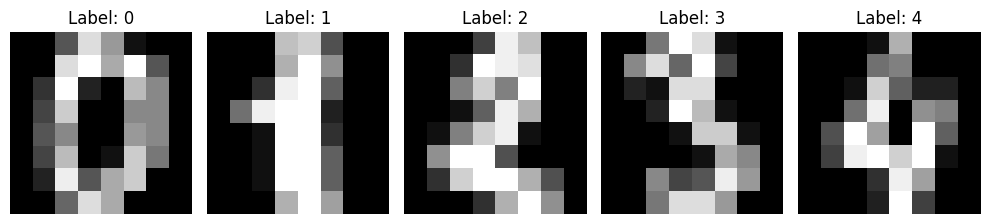


SVC accuracy on flattened 8x8 pixel vectors: 0.9889


In [9]:
from sklearn.datasets import load_digits
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

digits = load_digits()   # 8x8 grayscale handwritten digit images, bundled with sklearn -- no download needed
print("Raw image shape (per sample):", digits.images[0].shape)
print("Flattened feature vector shape (what Scikit-learn actually receives):", digits.data[0].shape)

fig, axes = plt.subplots(1, 5, figsize=(10, 2.5))
for ax, img, label in zip(axes, digits.images[:5], digits.target[:5]):
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

X_img_train, X_img_test, y_img_train, y_img_test = train_test_split(digits.data, digits.target, test_size=0.25, random_state=42)
svc_img = SVC(gamma=0.001).fit(X_img_train, y_img_train)
preds_img = svc_img.predict(X_img_test)
print(f"\nSVC accuracy on flattened 8x8 pixel vectors: {accuracy_score(y_img_test, preds_img):.4f}")


### Line-by-Line Explanation
- `digits.images[0].shape` is `(8, 8)` — a genuine 2D image; `digits.data[0].shape` is `(64,)` — the **same** image, flattened into a 1D vector, since Scikit-learn's `X` must be `(n_samples, n_features)` (Chapter 3) with no special-cased 2D-image support at all. Each pixel simply becomes one feature.
- This works reasonably well specifically because these images are small (8×8), grayscale, and centrally-cropped/normalized — a favorable case for treating raw pixel values as flat, directly meaningful features. On larger, more complex, real-world photographs, this flattening approach breaks down badly: it discards all spatial structure (a shifted or rotated version of the same digit produces a completely different flattened vector), which is exactly the problem convolutional neural networks are specifically architected to solve.

### Where Classical Scikit-learn Genuinely Still Helps in a CV Context


In [10]:
# A genuinely useful modern pattern: use a PRETRAINED deep learning model purely as a
# feature extractor, then apply a classical Scikit-learn classifier on TOP of those embeddings
# -- this is real, common practice, not merely educational. (No actual deep model loaded here --
# this is a CONCEPTUAL sketch, since loading a real pretrained CNN is outside this course's scope.)

print("""
Conceptual pattern (not runnable without a deep learning library installed):

    from some_pretrained_model import extract_embeddings
    image_embeddings = extract_embeddings(raw_images)   # e.g., a 512 or 2048-dim vector per image,
                                                          # from a model already trained on millions of images

    # From here on, it's PURE Scikit-learn -- exactly like any other tabular problem:
    from sklearn.svm import SVC
    from sklearn.model_selection import cross_val_score
    classifier = SVC()
    scores = cross_val_score(classifier, image_embeddings, labels, cv=5)
""")

print("This 'pretrained embeddings + classical classifier' pattern is genuinely common in production:")
print("it avoids training a deep network from scratch (expensive, needs huge data) while still")
print("capturing rich learned visual features, then uses Scikit-learn's fast, simple, well-understood")
print("classifiers/evaluation tools on top -- often sufficient when the downstream classification")
print("task itself has a MODEST amount of labeled data, even if the embeddings model was trained on")
print("a huge, different, related dataset originally.")



Conceptual pattern (not runnable without a deep learning library installed):

    from some_pretrained_model import extract_embeddings
    image_embeddings = extract_embeddings(raw_images)   # e.g., a 512 or 2048-dim vector per image,
                                                          # from a model already trained on millions of images

    # From here on, it's PURE Scikit-learn -- exactly like any other tabular problem:
    from sklearn.svm import SVC
    from sklearn.model_selection import cross_val_score
    classifier = SVC()
    scores = cross_val_score(classifier, image_embeddings, labels, cv=5)

This 'pretrained embeddings + classical classifier' pattern is genuinely common in production:
it avoids training a deep network from scratch (expensive, needs huge data) while still
capturing rich learned visual features, then uses Scikit-learn's fast, simple, well-understood
classifiers/evaluation tools on top -- often sufficient when the downstream classification
task itself 

### When Deep Learning Becomes Necessary Instead
- Large, complex, real-world images where spatial structure (edges, textures, shapes at multiple scales) is essential and can't be adequately captured by flat pixel vectors or simple engineered features.
- Tasks requiring the model to *learn* its own feature representations end-to-end (rather than relying on hand-engineered or externally-pretrained features).
- Any task where state-of-the-art performance genuinely requires a large, deep, specialized architecture (modern image classification, object detection, segmentation).

### Common Mistakes
- Attempting to flatten large, real-world (not small/simplified) images into raw pixel feature vectors for a Scikit-learn classifier — loses all spatial structure and rarely performs competitively versus even a modest CNN.
- Assuming Scikit-learn has no legitimate role in computer vision at all — the "pretrained embeddings + classical classifier" pattern is genuinely common and effective in real production systems, especially with limited labeled data for the specific downstream task.

### Interview Insight
**Q: When might it make sense to use a Scikit-learn classifier as part of an image classification system, rather than training a deep neural network end-to-end?**
A: When you have limited labeled data for your specific task but can access a model already pretrained on a large, related dataset — extracting that pretrained model's learned embeddings (rich, spatially-aware feature vectors) and then training a fast, simple Scikit-learn classifier (SVM, Logistic Regression, Random Forest) on top of those embeddings is often a highly effective and vastly cheaper alternative to training or fine-tuning a full deep network from scratch. This "pretrained embeddings + classical classifier" pattern leverages deep learning's representation-learning strength while keeping the final classification step simple, fast, and well-understood via Scikit-learn's mature tooling — genuinely common in production systems with modest task-specific labeled data.

### Quiz (Chapter 65)
1. Why does flattening a raw image into a pixel vector lose important information that a CNN would otherwise capture?
2. What is the "pretrained embeddings + classical classifier" pattern, and why is it genuinely useful in practice?
3. When does a task genuinely require deep learning rather than classical Scikit-learn approaches?


---
# CHAPTER 66 — MODEL PERSISTENCE

## 1. Concept
`joblib` is Scikit-learn's recommended tool for saving (`dump`) and loading (`load`) fitted models to/from disk — essential the moment a model needs to be used **later**, in a **different process** (a production API, a scheduled batch job), than the one that trained it.

## 2. Saving and Loading a Full Pipeline


In [11]:
import joblib
import os
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Build and fit a full, realistic pipeline (exactly Chapter 21's style)
np.random.seed(66)
df_persist = pd.DataFrame({
    "age": np.random.normal(40, 12, 300),
    "income": np.random.normal(60000, 15000, 300),
    "city": np.random.choice(["NYC", "LA", "SF"], 300),
})
y_persist = np.random.randint(0, 2, 300)

persist_pipeline = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer()), ("scale", StandardScaler())]), ["age", "income"]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["city"]),
    ])),
    ("model", RandomForestClassifier(n_estimators=100, random_state=42)),
])
persist_pipeline.fit(df_persist, y_persist)

os.makedirs("/home/claude/models", exist_ok=True)
model_path = "/home/claude/models/churn_pipeline_v1.joblib"
joblib.dump(persist_pipeline, model_path)
print(f"Saved to {model_path}, size: {os.path.getsize(model_path):,} bytes")

# Simulate a COMPLETELY SEPARATE process loading the model later (e.g., a production API server)
loaded_pipeline = joblib.load(model_path)
print("\nLoaded pipeline type:", type(loaded_pipeline))
print("Prediction from the LOADED pipeline on new raw data:", loaded_pipeline.predict(df_persist.head(3)))
print("Matches original pipeline's prediction:",
      np.array_equal(loaded_pipeline.predict(df_persist.head(3)), persist_pipeline.predict(df_persist.head(3))))


Saved to /home/claude/models/churn_pipeline_v1.joblib, size: 1,345,851 bytes

Loaded pipeline type: <class 'sklearn.pipeline.Pipeline'>
Prediction from the LOADED pipeline on new raw data: [0 0 0]
Matches original pipeline's prediction: True


### Line-by-Line Explanation
- `joblib.dump(persist_pipeline, model_path)` — saves the **entire fitted Pipeline** (preprocessing AND model, with every learned parameter) as one artifact — critically, this means the production inference code never needs to separately reconstruct or re-fit the preprocessing steps; it just loads one object and calls `.predict()` on raw new data, exactly as `loaded_pipeline.predict(df_persist.head(3))` demonstrates.
- Saving the **whole pipeline**, not just the final model, is essential and deliberate: if only the `RandomForestClassifier` were saved (without the fitted `ColumnTransformer`), the production code would need to separately reconstruct identical preprocessing — a serious, easy-to-get-wrong duplication of logic between training and inference code, and a direct route to exactly the kind of train/inference mismatch that silently degrades production model quality.

### Why `joblib` Over Plain `pickle`
`joblib` is built on top of (and largely compatible with) Python's standard `pickle` module, but is specifically optimized for objects containing large NumPy arrays (like a fitted model's learned coefficients or a Random Forest's many trees) — often producing smaller files and faster save/load times for these specifically ML-shaped objects, which is exactly why Scikit-learn's own documentation recommends it as the standard choice.

### Version and Environment Compatibility — A Serious, Real Risk


In [12]:
import sklearn
print("This model was saved with scikit-learn version:", sklearn.__version__)
print("\nA model saved with one scikit-learn version is NOT guaranteed to load correctly")
print("(or may load but behave subtly differently) with a DIFFERENT scikit-learn version --")
print("internal representations of fitted estimators can and do change between releases.")
print("\nBEST PRACTICE: pin and record the exact scikit-learn (and NumPy, Python) version")
print("used to train a persisted model, and use the SAME versions when loading it later,")
print("ideally via a containerized/pinned environment (requirements.txt / Docker) --")
print("this is a genuine, common source of production incidents when ignored.")


This model was saved with scikit-learn version: 1.6.1

A model saved with one scikit-learn version is NOT guaranteed to load correctly
(or may load but behave subtly differently) with a DIFFERENT scikit-learn version --
internal representations of fitted estimators can and do change between releases.

BEST PRACTICE: pin and record the exact scikit-learn (and NumPy, Python) version
used to train a persisted model, and use the SAME versions when loading it later,
ideally via a containerized/pinned environment (requirements.txt / Docker) --
this is a genuine, common source of production incidents when ignored.


### Security — `joblib.load()` Is NOT Inherently Safe for Untrusted Files
`joblib.load()` (like `pickle.load()`, which it's built on) can execute arbitrary code embedded in a malicious file during deserialization — **never** call `joblib.load()` on a model file from an untrusted or unverified source, exactly as you would never run an executable file from an unknown source. This is a genuine security consideration, not a theoretical one, and is explicitly why loading serialized models should be treated with the same caution as running any other untrusted code.

### Common Mistakes
- Saving only the final model, not the full preprocessing + model Pipeline — forces error-prone manual reconstruction of preprocessing logic at inference time, risking a training/inference mismatch.
- Loading a `joblib` file from an untrusted source without considering the security implications — this is a genuine attack vector (arbitrary code execution), not just a data-integrity concern.
- Not recording/pinning the exact library versions used to train a persisted model — a very common, very real cause of "the model behaves differently after we redeployed it" production incidents.

### Best Practices
- Always persist the **entire fitted Pipeline**, never just the bare final model.
- Record and pin the exact Python/NumPy/Scikit-learn versions (e.g., in a `requirements.txt` or a container image) alongside every persisted model artifact.
- Treat `joblib.load()` exactly like executing untrusted code — only load models from sources you trust and can verify.

### Interview Insight
**Q: Why should you persist the entire fitted Pipeline (preprocessing + model) rather than just the trained classifier alone?**
A: If only the classifier is saved, the production/inference code must separately re-implement the exact same preprocessing steps (imputation values, scaling parameters, one-hot encoding categories) that were used during training — any discrepancy between the training-time and inference-time preprocessing (even a subtle one, like a slightly different imputation strategy or a missing category-handling edge case) silently produces incorrect predictions with no error raised, since the model will happily make predictions on whatever numbers it's given, correct or not. Persisting the entire fitted Pipeline as one artifact guarantees inference always uses *exactly* the same preprocessing logic and learned parameters that training used, eliminating this entire class of training/inference mismatch bugs by construction.

### Quiz (Chapter 66)
1. Why is `joblib` generally preferred over plain `pickle` for persisting Scikit-learn models specifically?
2. Why must the entire fitted Pipeline be saved, not just the final classifier?
3. What security risk does `joblib.load()` carry, and how should it be treated as a result?
4. Why is recording the exact library versions used to train a model a genuine production best practice, not just a nicety?

### Chapter 66 Summary
- `joblib.dump()`/`load()` persist fitted Scikit-learn objects — always the entire Pipeline, never just the bare model.
- Version/environment pinning and treating `joblib.load()` as executing untrusted code are both genuine, real-world production concerns, not theoretical caveats.

---

## END OF NOTEBOOK 11 — What You Should Now Be Able To Do
- Profile a full ML pipeline stage by stage to find genuine bottlenecks before optimizing, and apply `n_jobs=-1` correctly without oversubscription.
- Explain why sparse matrices matter for high-cardinality categorical/text data, and why centering/scaling operations must be handled carefully (`with_mean=False`) to preserve sparsity.
- Build a complete classical NLP pipeline with `TfidfVectorizer`, correctly parameterized, and interpret which words drive a text classifier's predictions.
- Tune a vectorizer and classifier jointly inside one Pipeline via `GridSearchCV`, avoiding text-specific leakage.
- Understand where classical Scikit-learn genuinely still fits in computer vision (small images, or pretrained-embeddings + classical classifier) versus where deep learning becomes necessary.
- Persist and reload a complete, production-ready Pipeline with `joblib`, understanding the version-compatibility and security considerations involved.

## Before Moving to Notebook 12 (Chapters 67–72: Model Versioning, Production Inference, API/Deployment Awareness, MLOps Connection, Model Monitoring, End-to-End Project #1 — Customer Churn Prediction System)